# Databases - Hydrology

This tutorial covers `HydrologyDB`, the database for river reaches. Each reach is a site, a point at its gauge or outlet, and it may have a *catchment*, the polygon that drains to it. Sites and catchments are two layers of the same GeoPackage. Every catchment needs a site, and a site has at most one catchment, but it may have none. That matters in practice: gauges are usually known from the start, while catchments arrive over time, as someone draws or generates them.

The example is a river with six gauges, of which a regional dataset covers only three.

```{seealso}
Check out the {doc}`Databases - Spatial <databases_03_spatial>` tutorial first, which introduces the `columns_map` and setup files.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point, box

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.databases import HydrologyDB

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/databases")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\databases


## The sources

The gauges run along the river from west to east. Each catchment is simplified to a box, from the headwaters down to its gauge, so catchments overlap as they nest downstream. Lets keep a helper that makes one, with its area, in a metric CRS. The gauges come in one file, and the regional dataset in another, in a different CRS. It holds three of our gauges and two from another river:

In [2]:
CRS = "EPSG:4674"  # SIRGAS 2000, geographic
CRS_METRIC = "EPSG:31982"  # SIRGAS 2000 / UTM zone 22S

codes = [f"R00{i}" for i in range(1, 7)]
x_gauge = dict(zip(codes, [-53.0, -52.5, -52.0, -51.5, -51.0, -50.5]))


def make_catchment(code, column="Code"):
    # a box from the headwaters to the gauge, with its area in km2
    gdf = gpd.GeoDataFrame({column: [code]}, geometry=[box(-53.5, -30.4, x_gauge.get(code, -53.2), -29.6)], crs=CRS)
    return gdf.assign(Area=gdf.to_crs(CRS_METRIC).area.round(-6) / 1e6)


gauges = gpd.GeoDataFrame(
    data={"GaugeCode": codes, "GaugeName": ["Upper", "Bend", "Mill", "Bridge", "Ferry", "Mouth"]},
    geometry=[Point(x_gauge[c], -30.0) for c in codes],
    crs=CRS,
)
file_gauges = OUTPUT_DIR / "gauges.gpkg"
gauges.to_file(filename=file_gauges, layer="gauges", driver="GPKG")

regional = pd.concat([make_catchment(code=c, column="GaugeCode") for c in ["R001", "R002", "R003", "R901", "R902"]], ignore_index=True)
regional = regional.rename(columns={"Area": "AreaKm2"}).assign(Survey=2019).to_crs(CRS_METRIC)
file_regional = OUTPUT_DIR / "regional.gpkg"
regional.to_file(filename=file_regional, layer="catchments", driver="GPKG")
regional.drop(columns="geometry")

,GaugeCode,AreaKm2,Survey
0,R001,4280.0,2019
1,R002,8558.0,2019
2,R003,12834.0,2019
3,R901,2568.0,2019
4,R902,2568.0,2019


Two datasets will live here. Streamflow is measured at the gauge, while rainfall is averaged over the catchment. Both are records of the site, and the `extent` of the spec tells which is which:

In [3]:
def make_spec(name, abstract, variable, statistic, source, extent):
    # one monthly spec
    return {
        "name": name,
        "abstract": abstract,
        "method": "synthetic",
        "timestep": "1M",
        "extent": extent,
        "scale": 1,
        "offset": 0,
        "start": "2016-01-01",
        "end": None,
        "variable_name": variable,
        "statistic_name": statistic,
        "source_name": source,
    }


specs = [
    make_spec("Q_MONTHLY", "Monthly mean streamflow", "standard streamflow", "mean", "ANA", "gauge"),
    make_spec("PPT_MONTHLY_AREAL", "Monthly rainfall over the catchment", "precipitation", "sum", "CHIRPS v2.0", "catchment"),
]
file_specs = OUTPUT_DIR / "reaches_specs.json"
_ = file_specs.write_text(json.dumps(specs, indent=2), encoding="utf-8")

## Creating the database

The setup takes an optional `catchments` section, read like `spatial`. In its `columns_map`, the `name` entry is the source column holding the site names, here also called `GaugeCode`, and each catchment takes the name of its site. As anywhere in a setup, it can be a dict or a file:

`````{tab-set}
:sync-group: setup

````{tab-item} TOML
:sync: toml

```toml
[database]
path = "outputs/databases/reaches_db.gpkg"

[specs]
path = "outputs/databases/reaches_specs.json"

[spatial]
file = "outputs/databases/gauges.gpkg"
layer = "gauges"

[spatial.columns_map]
name = "GaugeCode"
gauge_title = "GaugeName"

[catchments]
file = "outputs/databases/regional.gpkg"
layer = "catchments"

[catchments.columns_map]
name = "GaugeCode"
area_km2 = "AreaKm2"
```
````

````{tab-item} JSON
:sync: json

```json
{
  "database": {"path": "outputs/databases/reaches_db.gpkg"},
  "specs": {"path": "outputs/databases/reaches_specs.json"},
  "spatial": {
    "file": "outputs/databases/gauges.gpkg",
    "layer": "gauges",
    "columns_map": {
      "name": "GaugeCode",
      "gauge_title": "GaugeName"
    }
  },
  "catchments": {
    "file": "outputs/databases/regional.gpkg",
    "layer": "catchments",
    "columns_map": {
      "name": "GaugeCode",
      "area_km2": "AreaKm2"
    }
  }
}
```
````
`````

When catchments are not available yet, the section is simply left out, and the layer starts empty. Lets write the TOML version and pass its path to `.new()`:

In [4]:
file_setup = OUTPUT_DIR / "reaches_setup.toml"
file_setup.write_text(
    f"""[database]
path = "{(OUTPUT_DIR / 'reaches_db.gpkg').as_posix()}"

[specs]
path = "{file_specs.as_posix()}"

[spatial]
file = "{file_gauges.as_posix()}"
layer = "gauges"

[spatial.columns_map]
name = "GaugeCode"
gauge_title = "GaugeName"

[catchments]
file = "{file_regional.as_posix()}"
layer = "catchments"

[catchments.columns_map]
name = "GaugeCode"
area_km2 = "AreaKm2"
""",
    encoding="utf-8",
)
db = HydrologyDB(name="River")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    db.new(config=file_setup, overwrite=True)
print(*[w.message for w in caught], sep="\n")

2 feature(s) naming no site were skipped


The two features from the other river name no site, so they were skipped with a warning. With `skip_unmatched = false` in the section, they would be an error instead. If nothing matched at all, it is an error either way, since that usually means the `name` entry points to the wrong column.

The layer holds what matched, reprojected to the CRS of the sites. The `Survey` column stayed out, as it is not in the map. The `.missing_catchments()` method tells which sites still have none:

In [5]:
print("Missing:", db.missing_catchments())
db.get_catchments().drop(columns="geometry")

Missing: ['R004', 'R005', 'R006']


,id,name,area_km2
0,1,R001,4280.0
1,2,R002,8558.0
2,3,R003,12834.0


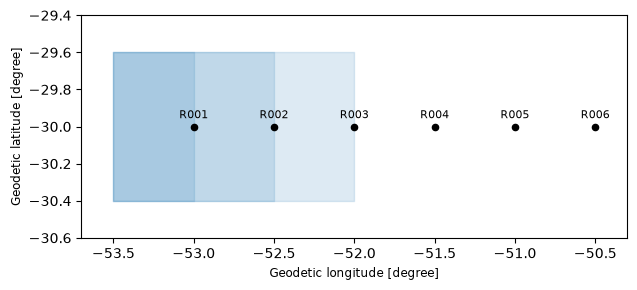

In [6]:
def plot_network(db):
    # shaded catchments, with the gauges on top
    fig, ax = plt.subplots(figsize=(8, 3))
    db.get_catchments().plot(ax=ax, facecolor="tab:blue", edgecolor="tab:blue", alpha=0.15)
    sites = db.get_features()
    sites.plot(ax=ax, color="black", markersize=20, zorder=3)
    for site in sites.itertuples():
        ax.annotate(site.name, (site.geometry.x, site.geometry.y), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xlim(-53.7, -50.3)
    ax.set_ylim(-30.6, -29.4)
    plt.tight_layout()
    plt.show()


plot_network(db=db)

## Adding catchments later

The `.append_catchment()` method adds one catchment to one site, and keeps the geometry apart from the attributes. The geometry always comes from a spatial file. Attributes may come from that file or from a dict, and anything left out stays empty.

### A drawn polygon

Someone draws the catchment of `R004` in a GIS and saves it. The file holds one feature, with no code and no area, so the site is given by `name`, and the area by value. The polygon comes in another CRS here, and is reprojected to the layer:

In [7]:
drawn = make_catchment(code="R004").to_crs(CRS_METRIC)
area_drawn = float(drawn["Area"].iloc[0])
file_drawn = OUTPUT_DIR / "drawn.gpkg"
drawn[["geometry"]].to_file(filename=file_drawn, driver="GPKG")

db.append_catchment(name="R004", file=file_drawn, attributes={"area_km2": area_drawn})
db.get_catchments(names="R004").drop(columns="geometry")

,id,name,area_km2
0,4,R004,17110.0


### One feature of a larger file

Later, a national dataset with many catchments comes along. With `name` in the `columns_map`, that source column picks the feature. The method first reads only that column to find the row, and then reads only that row, so the rest of the file is never loaded. No match, or more than one, is an error:

In [8]:
national = pd.concat([make_catchment(code=c) for c in ["R005", "R006", "R903", "R904"]], ignore_index=True)
file_national = OUTPUT_DIR / "national.gpkg"
national.to_file(filename=file_national, layer="all", driver="GPKG")

db.append_catchment(
    name="R005",
    file=file_national,
    layer="all",
    columns_map={"name": "Code", "area_km2": "Area"},
)
db.get_catchments(names="R005").drop(columns="geometry")

,id,name,area_km2
0,5,R005,21385.0


### Generated in Python

A catchment generated by a script is already a `GeoDataFrame`, so `.insert_catchments()` takes it directly. It also takes many at once, which suits bulk loads better than repeated appends, and skips features naming no site, as at creation:

Missing: []


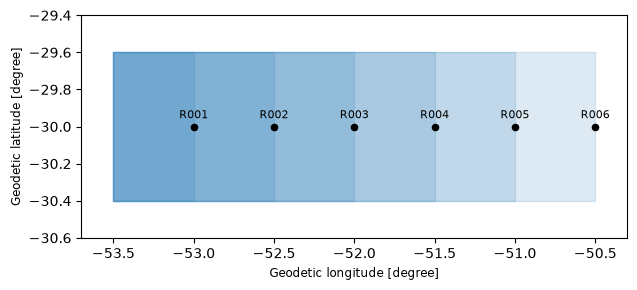

In [9]:
generated = make_catchment(code="R006")
db.insert_catchments(gdf=generated, columns_map={"name": "Code", "area_km2": "Area"})
print("Missing:", db.missing_catchments())
plot_network(db=db)

### What is refused

Catchments without a site and second catchments for a site are refused. These rules also live in the file itself, as a unique index and a trigger, so they hold for any tool writing through GDAL:

In [10]:
for name in ["R999", "R001"]:
    try:
        db.append_catchment(name=name, file=file_drawn)
    except ValueError as error:
        print(error)

Name 'R999' not in the sites layer
Site 'R001' already has a catchment


### Replacing and new attributes

A better delineation replaces the old one with `overwrite=True`. By default, the layer keeps the columns it was created with, so an unknown attribute is refused, and a typo does not become a column. With `add_columns=True`, the column is added, typed from its value, and the other rows stay empty:

In [11]:
values = {"area_km2": area_drawn, "delineation": "manual"}
try:
    db.append_catchment(name="R004", file=file_drawn, attributes=values, overwrite=True)
except ValueError as error:
    print(error)

db.append_catchment(name="R004", file=file_drawn, attributes=values, overwrite=True, add_columns=True)
db.get_catchments().drop(columns="geometry")

Column(s) ['delineation'] not in the catchments layer


,id,name,area_km2,delineation
0,1,R001,4280.0,NaN
1,2,R002,8558.0,NaN
2,3,R003,12834.0,NaN
3,5,R005,21385.0,NaN
4,6,R006,25660.0,NaN
5,8,R004,17110.0,manual


A replacement is written as a new row, so the catchment takes a new `id`. Nothing depends on it: catchments are linked to sites by `name`, and the `id` of a catchment is not the `id` of its site.

## Records

Records always point to the site, by `site_id` or `site_name`, whichever spec they belong to. Rainfall falls over the catchment and streamflow is read at the gauge, but both are loaded the same way:

In [12]:
rng = np.random.default_rng(seed=5)  # ensure reproducibility
dates = pd.date_range(start="2016-01-01", end="2020-12-01", freq="MS")
season = np.cos(2 * np.pi * (dates.month - 1) / 12)
seconds = dates.days_in_month * 86400

areas = db.get_catchments().set_index("name")["area_km2"]
rain = 130 * (1 - 0.3 * season) * rng.gamma(shape=6, scale=1 / 6, size=len(dates))
frames_q, frames_p = [], []
for code in codes:
    flow = areas[code] * 1e6 * 0.4 * rain / 1000 / seconds
    frames_q.append(pd.DataFrame({"datetime": dates, "value": flow, "site_name": code}))
    frames_p.append(pd.DataFrame({"datetime": dates, "value": rain * rng.normal(1, 0.03, len(dates)), "site_name": code}))
with db.transaction():
    db.insert_records(dataframe=pd.concat(frames_q, ignore_index=True), spec_name="Q_MONTHLY", flag=1)
    db.insert_records(dataframe=pd.concat(frames_p, ignore_index=True), spec_name="PPT_MONTHLY_AREAL", flag=1)
db.query_records(query_dict={"site_name": "R004", "start": "2016-01-01", "end": "2016-02-01"})[["datetime", "spec_name", "value", "site_id"]]

,datetime,spec_name,value,site_id
0,2016-01-01 00:00:00+00:00,Q_MONTHLY,153.624864,4
1,2016-02-01 00:00:00+00:00,Q_MONTHLY,223.226031,4
2,2016-01-01 00:00:00+00:00,PPT_MONTHLY_AREAL,58.200084,4
3,2016-02-01 00:00:00+00:00,PPT_MONTHLY_AREAL,84.652797,4


Joining the three pieces goes through the names. Sites map `site_id` to `name`, and catchments map `name` to their attributes. Dividing the mean flow by the area gives the specific discharge, which is about the same along the river, as this synthetic runoff should be:

In [13]:
flow = db.query_records(query_dict={"spec_name": "Q_MONTHLY"}).groupby("site_id")["value"].mean().rename("q_m3s")
table = (
    db.get_features()[["id", "name", "gauge_title"]]
    .merge(flow, left_on="id", right_index=True)
    .merge(db.get_catchments()[["name", "area_km2"]], on="name", how="left")
)
table["q_ls_km2"] = 1000 * table["q_m3s"] / table["area_km2"]
table.round(1)

,id,name,gauge_title,q_m3s,area_km2,q_ls_km2
0,1,R001,Upper,80.9,4280.0,18.9
1,2,R002,Bend,161.7,8558.0,18.9
2,3,R003,Mill,242.5,12834.0,18.9
3,4,R004,Bridge,323.3,17110.0,18.9
4,5,R005,Ferry,404.1,21385.0,18.9
5,6,R006,Mouth,484.9,25660.0,18.9


The left join keeps every site, so a site still missing its catchment would show an empty area, instead of dropping out of the table.

The file holds both layers, and both open in QGIS next to the tables of the database:

In [14]:
db.close()
gpd.list_layers(OUTPUT_DIR / "reaches_db.gpkg")

,name,geometry_type
0,sites,Point
1,catchments,MultiPolygon
2,variables,NaN
3,flags,NaN
4,sources,NaN
5,statistics,NaN
6,specs,NaN
7,records,NaN
